In [58]:
!zip -r resunet_aspect10_mod_1_outputs.zip /content/drive/MyDrive/resunet_mod1_long_multiskip_outputs

  adding: content/drive/MyDrive/resunet_mod1_long_multiskip_outputs/ (stored 0%)
  adding: content/drive/MyDrive/resunet_mod1_long_multiskip_outputs/validation_predicted_masks/ (stored 0%)
  adding: content/drive/MyDrive/resunet_mod1_long_multiskip_outputs/validation_predicted_masks/Agg_Crushed_Red_S_GLC_03_prediction.png (deflated 10%)
  adding: content/drive/MyDrive/resunet_mod1_long_multiskip_outputs/validation_predicted_masks/Agg_Crushed_Clear_M_GLC_03_prediction.png (deflated 8%)
  adding: content/drive/MyDrive/resunet_mod1_long_multiskip_outputs/validation_predicted_masks/Agg_Rounded_Black_M_HLC_03_prediction.png (deflated 7%)
  adding: content/drive/MyDrive/resunet_mod1_long_multiskip_outputs/validation_metrics_summary.csv (deflated 39%)
  adding: content/drive/MyDrive/resunet_mod1_long_multiskip_outputs/training_dice.png (deflated 12%)
  adding: content/drive/MyDrive/resunet_mod1_long_multiskip_outputs/validation_metrics_bar.png (deflated 21%)
  adding: content/drive/MyDrive/re

TensorFlow: 2.21.0
Visible GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Total paired images: 30
Train: 24 (80.0%)
Validation: 3 (10.0%)
Test: 3 (10.0%)
Saved split manifest: /content/drive/MyDrive/resunet_mod2_fixedkernel_outputs/dataset_split_manifest.csv


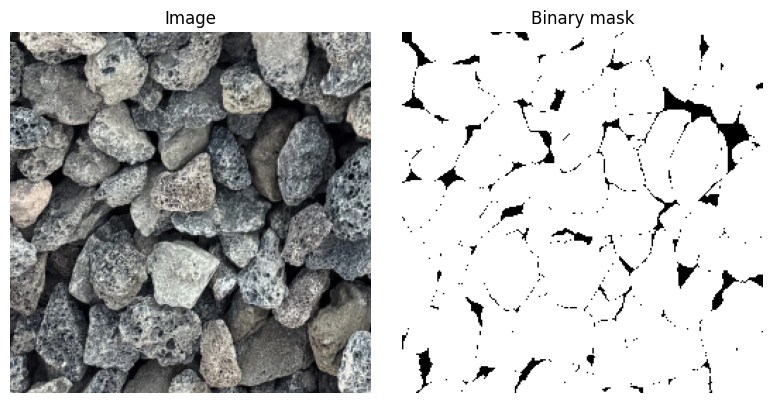

In [60]:
import os
import glob
import random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEED = 42
IMG_SIZE = (256, 256)
BATCH_SIZE = 1
EPOCHS = 50
LEARNING_RATE = 3e-4
BOUNDARY_TOLERANCE_PX = 2
PREDICTION_THRESHOLD = 0.5
IMAGE_DIR = '/content/ASPECT-10/ASPECT-10/IMAGES'
MASK_DIR = '/content/ASPECT-10/ASPECT-10/Binary_Mask'
OUTPUT_DIR = '/content/drive/MyDrive/resunet_mod2_fixedkernel_outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

for directory, label in ((IMAGE_DIR, 'IMAGE_DIR'), (MASK_DIR, 'MASK_DIR')):
    if not os.path.isdir(directory):
        raise FileNotFoundError(f'{label} does not exist: {directory}. Update the path in this cell.')

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
print('TensorFlow:', tf.__version__)
print('Visible GPU(s):', tf.config.list_physical_devices('GPU'))

VALID_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

def list_image_files(directory):
    return sorted(str(p) for p in Path(directory).iterdir() if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS)

def get_pairs(image_dir, mask_dir):
    images = list_image_files(image_dir)
    masks = list_image_files(mask_dir)
    image_map = {Path(p).stem: p for p in images}
    mask_map = {Path(p).stem: p for p in masks}
    if len(image_map) != len(images) or len(mask_map) != len(masks):
        raise ValueError('Duplicate file stems were found. Each image and mask must have a unique matching filename stem.')
    missing_masks = sorted(set(image_map) - set(mask_map))
    missing_images = sorted(set(mask_map) - set(image_map))
    if missing_masks or missing_images:
        raise ValueError(f'Image-mask pairing is incomplete. Images without masks: {missing_masks[:10]}; masks without images: {missing_images[:10]}. All samples must be paired before splitting.')
    pairs = [(image_map[k], mask_map[k]) for k in sorted(image_map)]
    if len(pairs) < 10:
        raise ValueError(f'At least 10 paired images are required for an 80/10/10 split; found {len(pairs)}.')
    return pairs

def load_image_mask(img_path, mask_path):
    image = cv2.imread(os.fspath(img_path), cv2.IMREAD_COLOR)
    mask = cv2.imread(os.fspath(mask_path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f'Could not read image: {img_path}')
    if mask is None:
        raise ValueError(f'Could not read mask: {mask_path}')
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
    mask = cv2.resize(mask, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_NEAREST)
    mask = (mask > 127).astype(np.float32)[..., np.newaxis]
    return image, mask

def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(load_image_mask, [img_path, mask_path], [tf.float32, tf.float32])
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return image, mask

def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image, mask = tf.image.flip_left_right(image), tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image, mask = tf.image.flip_up_down(image), tf.image.flip_up_down(mask)
    return image, mask

def make_dataset(sample_pairs, training=False):
    image_paths = [p[0] for p in sample_pairs]
    mask_paths = [p[1] for p in sample_pairs]
    ds = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if training:
        ds = ds.shuffle(buffer_size=len(sample_pairs), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(tf_load_image_mask, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

pairs = get_pairs(IMAGE_DIR, MASK_DIR)
train_pairs, holdout_pairs = train_test_split(pairs, test_size=0.20, random_state=SEED, shuffle=True)
val_pairs, test_pairs = train_test_split(holdout_pairs, test_size=0.50, random_state=SEED, shuffle=True)

sample_keys = lambda records: {Path(image_path).stem for image_path, _ in records}
train_keys, val_keys, test_keys = map(sample_keys, (train_pairs, val_pairs, test_pairs))
assert train_keys.isdisjoint(val_keys)
assert train_keys.isdisjoint(test_keys)
assert val_keys.isdisjoint(test_keys)
assert len(train_pairs) + len(val_pairs) + len(test_pairs) == len(pairs)
assert train_keys | val_keys | test_keys == sample_keys(pairs)

manifest_rows = []
for split_name, split_pairs in (('train', train_pairs), ('validation', val_pairs), ('test', test_pairs)):
    for image_path, mask_path in split_pairs:
        manifest_rows.append({'split': split_name, 'image_path': image_path, 'mask_path': mask_path, 'image_name': Path(image_path).name})
manifest_path = os.path.join(OUTPUT_DIR, 'dataset_split_manifest.csv')
pd.DataFrame(manifest_rows).to_csv(manifest_path, index=False)
train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs, training=False)
print(f'Total paired images: {len(pairs)}')
print(f'Train: {len(train_pairs)} ({len(train_pairs) / len(pairs):.1%})')
print(f'Validation: {len(val_pairs)} ({len(val_pairs) / len(pairs):.1%})')
print(f'Test: {len(test_pairs)} ({len(test_pairs) / len(pairs):.1%})')
print('Saved split manifest:', manifest_path)
_example_image, _example_mask = load_image_mask(*train_pairs[0])
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(_example_image)
axes[0].set_title('Image')
axes[1].imshow(_example_mask[..., 0], cmap='gray')
axes[1].set_title('Binary mask')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [61]:
def residual_block_initial(x, filters, strides=(1, 1), name='res_initial'):
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv1')(x)
    y = tf.keras.layers.BatchNormalization(name=f'{name}_bn1')(y)
    y = tf.keras.layers.Activation('relu', name=f'{name}_relu1')(y)
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[1], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv2')(y)
    shortcut = tf.keras.layers.Conv2D(filters, 1, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_shortcut_conv')(x)
    shortcut = tf.keras.layers.BatchNormalization(name=f'{name}_shortcut_bn')(shortcut)
    return tf.keras.layers.Add(name=f'{name}_add')([shortcut, y])

def residual_block(x, filters, strides=(1, 1), name='res_block'):
    input_channels = x.shape[-1]
    y = tf.keras.layers.BatchNormalization(name=f'{name}_bn1')(x)
    y = tf.keras.layers.Activation('relu', name=f'{name}_relu1')(y)
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv1')(y)
    y = tf.keras.layers.BatchNormalization(name=f'{name}_bn2')(y)
    y = tf.keras.layers.Activation('relu', name=f'{name}_relu2')(y)
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[1], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv2')(y)
    if strides[0] != 1 or input_channels != filters:
        shortcut = tf.keras.layers.Conv2D(filters, 1, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_shortcut_conv')(x)
        shortcut = tf.keras.layers.BatchNormalization(name=f'{name}_shortcut_bn')(shortcut)
    else:
        shortcut = x
    return tf.keras.layers.Add(name=f'{name}_add')([shortcut, y])

@tf.keras.utils.register_keras_serializable(package='RockSegmentation')
class FixedKernelLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        kwargs['trainable'] = False
        super().__init__(**kwargs)

    def build(self, input_shape):
        channels = int(input_shape[-1])
        sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
        sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32)
        laplacian = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)
        def depthwise_kernel(base_kernel):
            kernel = np.zeros((3, 3, channels, 1), dtype=np.float32)
            for channel in range(channels):
                kernel[:, :, channel, 0] = base_kernel
            return tf.constant(kernel, dtype=tf.float32)
        self.k_sobel_x = depthwise_kernel(sobel_x)
        self.k_sobel_y = depthwise_kernel(sobel_y)
        self.k_laplacian = depthwise_kernel(laplacian)
        super().build(input_shape)

    def call(self, x):
        sx = tf.nn.depthwise_conv2d(x, self.k_sobel_x, strides=[1, 1, 1, 1], padding='SAME')
        sy = tf.nn.depthwise_conv2d(x, self.k_sobel_y, strides=[1, 1, 1, 1], padding='SAME')
        lap = tf.nn.depthwise_conv2d(x, self.k_laplacian, strides=[1, 1, 1, 1], padding='SAME')
        return tf.concat([sx, sy, lap], axis=-1)

def merge_with_fixed_kernels(feat, filters, prefix):
    fixed_response = FixedKernelLayer(name=f'{prefix}_fixed_kernel')(feat)
    merged = tf.keras.layers.Concatenate(name=f'{prefix}_raw_edge_concat')([feat, fixed_response])
    merged = tf.keras.layers.Conv2D(filters, 1, padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{prefix}_compress')(merged)
    return tf.keras.layers.ReLU(name=f'{prefix}_compress_relu')(merged)

def fixed_kernel_decoder_block(x, skip, skip_fixed, filters, name):
    x = tf.keras.layers.UpSampling2D(size=(2, 2), interpolation='bilinear', name=f'{name}_upsample')(x)
    x = tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_up_projection')(x)
    x = tf.keras.layers.Concatenate(name=f'{name}_raw_fixed_concat')([x, skip, skip_fixed])
    return residual_block(x, filters, name=f'{name}_residual')

def build_resunet_fixedkernel(input_shape=(256, 256, 3), filters=(64, 128, 256, 512)):
    inputs = tf.keras.Input(shape=input_shape, name='image')
    e0 = residual_block_initial(inputs, filters[0], name='encoder_block0')
    e1 = residual_block(e0, filters[1], strides=(2, 1), name='encoder_block1')
    e2 = residual_block(e1, filters[2], strides=(2, 1), name='encoder_block2')
    e3 = residual_block(e2, filters[3], strides=(2, 1), name='encoder_block3')
    e0_fixed = merge_with_fixed_kernels(e0, filters[0], 'skip_e0')
    e1_fixed = merge_with_fixed_kernels(e1, filters[1], 'skip_e1')
    e2_fixed = merge_with_fixed_kernels(e2, filters[2], 'skip_e2')
    e3_fixed = merge_with_fixed_kernels(e3, filters[3], 'skip_e3')
    bridge = residual_block(e3, filters[3] * 2, strides=(2, 1), name='bridge')
    d3 = fixed_kernel_decoder_block(bridge, e3, e3_fixed, filters[3], 'decoder_block3')
    d2 = fixed_kernel_decoder_block(d3, e2, e2_fixed, filters[2], 'decoder_block2')
    d1 = fixed_kernel_decoder_block(d2, e1, e1_fixed, filters[1], 'decoder_block1')
    d0 = fixed_kernel_decoder_block(d1, e0, e0_fixed, filters[0], 'decoder_block0')
    logits = tf.keras.layers.Conv2D(1, 1, padding='same', activation=None, name='segmentation_logits')(d0)
    return tf.keras.Model(inputs=inputs, outputs=logits, name='ResUNet_FixedKernel')

def binary_from_logits(y_true, y_pred):
    return tf.cast(y_true >= 0.5, tf.float32), tf.cast(y_pred >= 0.0, tf.float32)

def binary_accuracy_logits(y_true, y_pred):
    y_true, y_pred = binary_from_logits(y_true, y_pred)
    return tf.reduce_mean(tf.cast(tf.equal(y_true, y_pred), tf.float32))

def dice_coef_logits(y_true, y_pred, smooth=1e-7):
    y_true, y_pred = binary_from_logits(y_true, y_pred)
    y_true, y_pred = tf.reshape(y_true, [-1]), tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

def iou_coef_logits(y_true, y_pred, smooth=1e-7):
    y_true, y_pred = binary_from_logits(y_true, y_pred)
    y_true, y_pred = tf.reshape(y_true, [-1]), tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

PAPER_FILTERS = (64, 128, 256, 512)
model = build_resunet_fixedkernel(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3), filters=PAPER_FILTERS)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss=tf.keras.losses.BinaryCrossentropy(from_logits=True), metrics=[binary_accuracy_logits, dice_coef_logits, iou_coef_logits])
model.summary()

Model: "ResUNet_FixedKernel"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 256, 256,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_con… │ (None, 256, 256,  │      1,728 │ image[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_bn1  │ (None, 256, 256,  │        256 │ encoder_block0_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_sho… │ (None, 256, 256,  │        192 │ image[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_rel… │ (None, 256, 256,  │          0 │ encoder_block0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_sho… │ (None, 256, 256,  │        256 │ encoder_block0_s… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_con… │ (None, 256, 256,  │     36,864 │ encoder_block0_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_add  │ (None, 256, 256,  │          0 │ encoder_block0_s… │
│ (Add)               │ 64)               │            │ encoder_block0_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_bn1  │ (None, 256, 256,  │        256 │ encoder_block0_a… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_rel… │ (None, 256, 256,  │          0 │ encoder_block1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_con… │ (None, 128, 128,  │     73,728 │ encoder_block1_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_bn2  │ (None, 128, 128,  │        512 │ encoder_block1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_sho… │ (None, 128, 128,  │      8,192 │ encoder_block0_a… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_rel… │ (None, 128, 128,  │          0 │ encoder_block1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_sho… │ (None, 128, 128,  │        512 │ encoder_block1_s… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_con… │ (None, 128, 128,  │    147,456 │ encoder_block1_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_add  │ (None, 128, 128,  │          0 │ encoder_block1_s

 Total params: 40,812,481 (155.69 MB)

 Trainable params: 40,793,025 (155.61 MB)

 Non-trainable params: 19,456 (76.00 KB)

Epoch 1/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step - binary_accuracy_logits: 0.7384 - dice_coef_logits: 0.8141 - iou_coef_logits: 0.7303 - loss: 0.6385
Epoch 1: val_dice_coef_logits improved from None to 0.96812, saving model to /content/drive/MyDrive/resunet_mod2_fixedkernel_outputs/best_resunet_mod2_fixedkernel.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/resunet_mod2_fixedkernel_outputs/best_resunet_mod2_fixedkernel.weights.h5
24/24 ━━━━━━━━━━━━━━━━━━━━ 62s 542ms/step - binary_accuracy_logits: 0.8706 - dice_coef_logits: 0.9170 - iou_coef_logits: 0.8664 - loss: 0.3353 - val_binary_accuracy_logits: 0.9383 - val_dice_coef_logits: 0.9681 - val_iou_coef_logits: 0.9383 - val_loss: 89.5718 - learning_rate: 3.0000e-04
Epoch 2/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step - binary_accuracy_logits: 0.9381 - dice_coef_logits: 0.9672 - iou_coef_logits: 0.9366 - loss: 0.1644
Epoch 2: val_dice_coef_logits did not improve from 0.96812
24/24 ━━━━━━━━━━━━━━━━━━━━ 6s 251ms/step

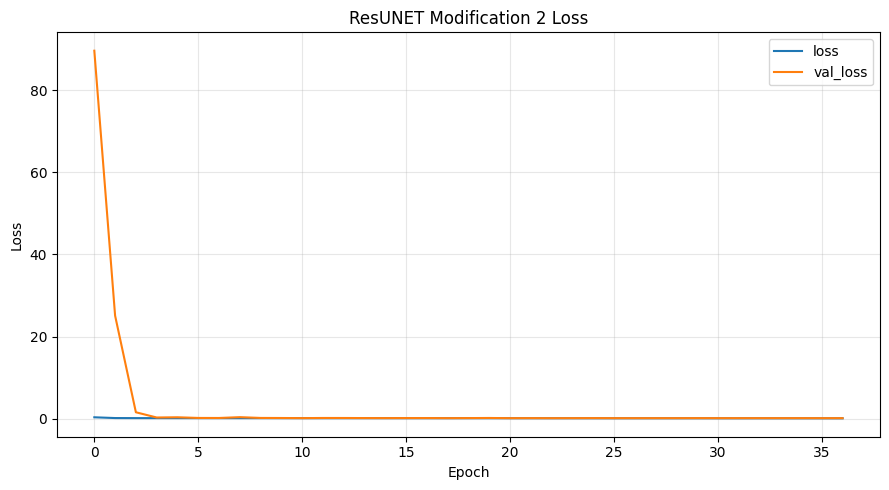

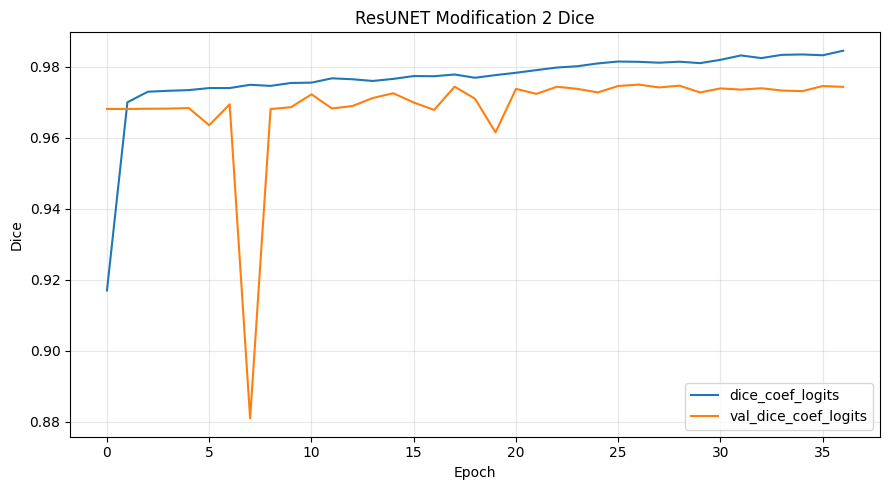

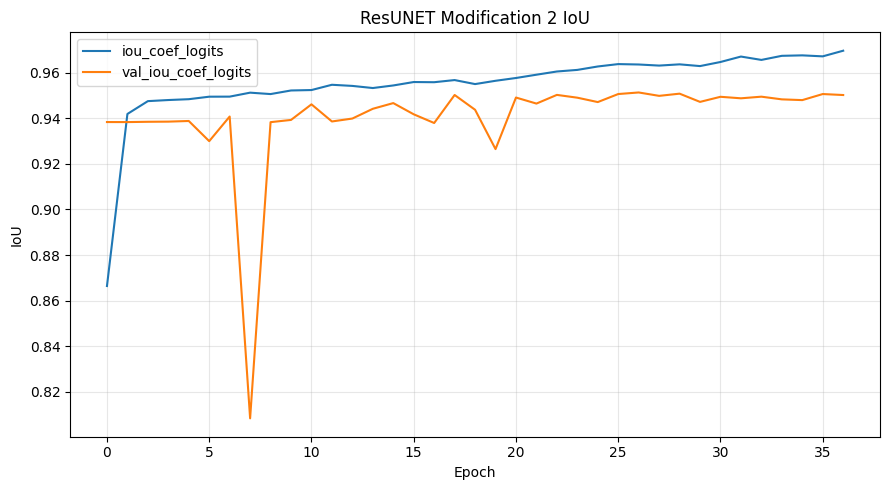

Best weights: /content/drive/MyDrive/resunet_mod2_fixedkernel_outputs/best_resunet_mod2_fixedkernel.weights.h5
Final weights: /content/drive/MyDrive/resunet_mod2_fixedkernel_outputs/final_resunet_mod2_fixedkernel.weights.h5
Training outputs: /content/drive/MyDrive/resunet_mod2_fixedkernel_outputs


In [62]:
BEST_WEIGHTS_PATH = os.path.join(OUTPUT_DIR, 'best_resunet_mod2_fixedkernel.weights.h5')
FINAL_WEIGHTS_PATH = os.path.join(OUTPUT_DIR, 'final_resunet_mod2_fixedkernel.weights.h5')

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(filepath=BEST_WEIGHTS_PATH, monitor='val_dice_coef_logits', mode='max', save_best_only=True, save_weights_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_dice_coef_logits', mode='max', patience=10, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_dice_coef_logits', mode='max', factor=0.5, patience=4, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.CSVLogger(os.path.join(OUTPUT_DIR, 'training_log.csv'))
]

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=1)
if not os.path.isfile(BEST_WEIGHTS_PATH):
    raise FileNotFoundError(f'Best checkpoint was not created: {BEST_WEIGHTS_PATH}')
model.load_weights(BEST_WEIGHTS_PATH)
model.save_weights(FINAL_WEIGHTS_PATH)
pd.DataFrame(history.history).to_csv(os.path.join(OUTPUT_DIR, 'training_history.csv'), index_label='epoch')
for metric_pairs, title, ylabel, filename in [
    (('loss', 'val_loss'), 'ResUNET Modification 2 Loss', 'Loss', 'training_loss.png'),
    (('dice_coef_logits', 'val_dice_coef_logits'), 'ResUNET Modification 2 Dice', 'Dice', 'training_dice.png'),
    (('iou_coef_logits', 'val_iou_coef_logits'), 'ResUNET Modification 2 IoU', 'IoU', 'training_iou.png')
]:
    plt.figure(figsize=(9, 5))
    for key in metric_pairs:
        if key in history.history:
            plt.plot(history.history[key], label=key)
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=160, bbox_inches='tight')
    plt.show()
print('Best weights:', BEST_WEIGHTS_PATH)
print('Final weights:', FINAL_WEIGHTS_PATH)
print('Training outputs:', OUTPUT_DIR)

Validation 1/3: Agg_Rounded_Black_M_HLC_03.jpg
Validation 2/3: Agg_Crushed_Clear_M_GLC_03.jpg
Validation 3/3: Agg_Crushed_Red_S_GLC_03.jpg


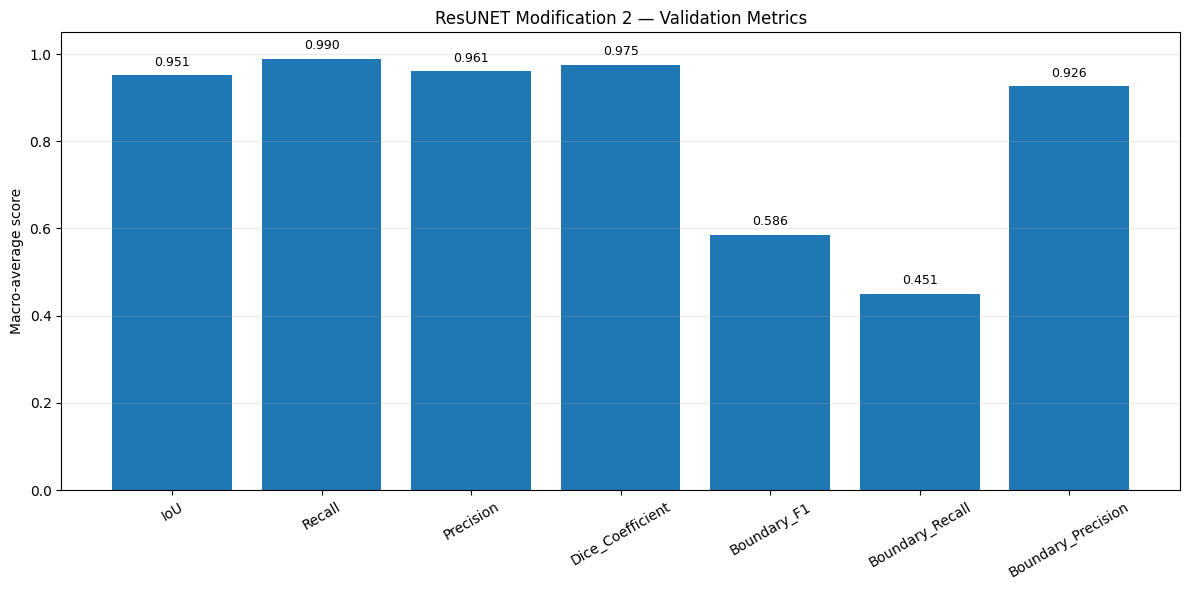


Validation macro-average metrics over 3 images
IoU                   : 0.9513 ± 0.0187
Recall                : 0.9898 ± 0.0139
Precision             : 0.9607 ± 0.0107
Dice_Coefficient      : 0.9750 ± 0.0098
Boundary_F1           : 0.5857 ± 0.1898
Boundary_Recall       : 0.4507 ± 0.2076
Boundary_Precision    : 0.9260 ± 0.0261
Test 1/3: LightAgg_Black_M_HTC_01.jpg
Test 2/3: Agg_Crushed_Red_S_GLC_01.jpg
Test 3/3: Agg_Crushed_Green_M_GLC_01.jpg


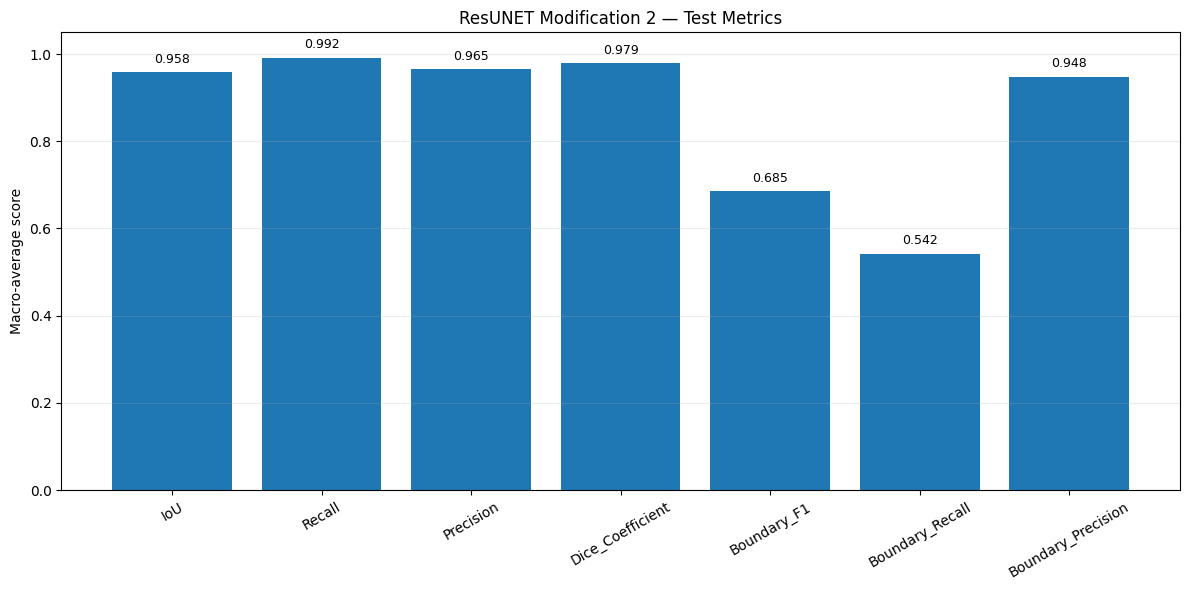


Test macro-average metrics over 3 images
IoU                   : 0.9581 ± 0.0141
Recall                : 0.9922 ± 0.0074
Precision             : 0.9654 ± 0.0143
Dice_Coefficient      : 0.9786 ± 0.0073
Boundary_F1           : 0.6850 ± 0.0954
Boundary_Recall       : 0.5422 ± 0.1130
Boundary_Precision    : 0.9485 ± 0.0126

Test predicted masks: /content/drive/MyDrive/resunet_mod2_fixedkernel_outputs/test_predicted_masks
Test comparison previews: /content/drive/MyDrive/resunet_mod2_fixedkernel_outputs/test_prediction_previews
Saved test mask count: 3
Dataset manifest: /content/drive/MyDrive/resunet_mod2_fixedkernel_outputs/dataset_split_manifest.csv
All artifacts: /content/drive/MyDrive/resunet_mod2_fixedkernel_outputs


In [63]:
METRIC_COLUMNS = ['IoU', 'Recall', 'Precision', 'Dice_Coefficient', 'Boundary_F1', 'Boundary_Recall', 'Boundary_Precision']

def safe_divide(numerator, denominator):
    return float(numerator / denominator) if denominator else 0.0

def binary_segmentation_metrics(y_true, y_pred):
    gt = np.asarray(y_true, dtype=bool)
    pred = np.asarray(y_pred, dtype=bool)
    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())
    precision = safe_divide(tp, tp + fp)
    recall = safe_divide(tp, tp + fn)
    iou = safe_divide(tp, tp + fp + fn)
    dice = safe_divide(2 * tp, 2 * tp + fp + fn)
    gt_u8 = gt.astype(np.uint8)
    pred_u8 = pred.astype(np.uint8)
    contour_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    gt_boundary = (gt_u8 - cv2.erode(gt_u8, contour_kernel, iterations=1)).astype(bool)
    pred_boundary = (pred_u8 - cv2.erode(pred_u8, contour_kernel, iterations=1)).astype(bool)
    tolerance_size = 2 * BOUNDARY_TOLERANCE_PX + 1
    tolerance_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (tolerance_size, tolerance_size))
    gt_dilated = cv2.dilate(gt_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)
    pred_dilated = cv2.dilate(pred_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)
    boundary_precision = safe_divide(int(np.logical_and(pred_boundary, gt_dilated).sum()), int(pred_boundary.sum()))
    boundary_recall = safe_divide(int(np.logical_and(gt_boundary, pred_dilated).sum()), int(gt_boundary.sum()))
    boundary_f1 = safe_divide(2 * boundary_precision * boundary_recall, boundary_precision + boundary_recall)
    return {'IoU': iou, 'Recall': recall, 'Precision': precision, 'Dice_Coefficient': dice, 'Boundary_F1': boundary_f1, 'Boundary_Recall': boundary_recall, 'Boundary_Precision': boundary_precision}

def evaluate_split(split_pairs, split_name, save_predictions=False):
    rows = []
    prediction_dir = os.path.join(OUTPUT_DIR, 'test_predicted_masks') if save_predictions else None
    preview_dir = os.path.join(OUTPUT_DIR, 'test_prediction_previews') if save_predictions else None
    if save_predictions:
        os.makedirs(prediction_dir, exist_ok=True)
        os.makedirs(preview_dir, exist_ok=True)
    for index, (image_path, mask_path) in enumerate(split_pairs, start=1):
        image, gt_mask = load_image_mask(image_path, mask_path)
        logits = model.predict(image[np.newaxis, ...], verbose=0)[0, ..., 0]
        pred_mask = tf.math.sigmoid(logits).numpy() >= PREDICTION_THRESHOLD
        gt_binary = gt_mask[..., 0] >= 0.5
        scores = binary_segmentation_metrics(gt_binary, pred_mask)
        rows.append({'image_name': Path(image_path).name, **scores})
        if save_predictions:
            stem = Path(image_path).stem
            mask_output_path = os.path.join(prediction_dir, f'{stem}_prediction.png')
            written = cv2.imwrite(mask_output_path, pred_mask.astype(np.uint8) * 255)
            if not written:
                raise IOError(f'Failed to save predicted mask: {mask_output_path}')
            overlay = image.copy()
            overlay[pred_mask] = 0.55 * overlay[pred_mask] + 0.45 * np.array([1.0, 0.0, 0.0])
            fig, axes = plt.subplots(1, 4, figsize=(14, 4))
            axes[0].imshow(image)
            axes[0].set_title('Image')
            axes[1].imshow(gt_binary, cmap='gray')
            axes[1].set_title('Ground truth')
            axes[2].imshow(pred_mask, cmap='gray')
            axes[2].set_title('Predicted mask')
            axes[3].imshow(np.clip(overlay, 0, 1))
            axes[3].set_title('Overlay')
            for ax in axes:
                ax.axis('off')
            fig.suptitle(Path(image_path).name)
            plt.tight_layout()
            fig.savefig(os.path.join(preview_dir, f'{stem}_comparison.png'), dpi=140, bbox_inches='tight')
            plt.close(fig)
        print(f'{split_name.title()} {index}/{len(split_pairs)}: {Path(image_path).name}')
    if not rows:
        raise RuntimeError(f'{split_name} split is empty.')
    result_df = pd.DataFrame(rows)
    summary_df = pd.DataFrame([{'metric': metric, 'macro_average': float(result_df[metric].mean()), 'std': float(result_df[metric].std(ddof=1)) if len(result_df) > 1 else 0.0, 'n_images': len(result_df)} for metric in METRIC_COLUMNS])
    result_df.to_csv(os.path.join(OUTPUT_DIR, f'{split_name}_metrics_per_image.csv'), index=False)
    summary_df.to_csv(os.path.join(OUTPUT_DIR, f'{split_name}_metrics_summary.csv'), index=False)
    fig, ax = plt.subplots(figsize=(12, 6))
    bars = ax.bar(summary_df['metric'], summary_df['macro_average'])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Macro-average score')
    ax.set_title(f'ResUNET Modification 2 — {split_name.title()} Metrics')
    ax.tick_params(axis='x', labelrotation=30)
    ax.grid(axis='y', alpha=0.25)
    for bar, value in zip(bars, summary_df['macro_average']):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f'{value:.3f}', ha='center', va='bottom', fontsize=9)
    plt.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, f'{split_name}_metrics_bar.png'), dpi=180, bbox_inches='tight')
    plt.show()
    print(f'\n{split_name.title()} macro-average metrics over {len(result_df)} images')
    for _, row in summary_df.iterrows():
        print(f"{row['metric']:<22}: {row['macro_average']:.4f} ± {row['std']:.4f}")
    return result_df, summary_df

val_results, val_summary = evaluate_split(val_pairs, 'validation', save_predictions=False)
test_results, test_summary = evaluate_split(test_pairs, 'test', save_predictions=True)
print('\nTest predicted masks:', os.path.join(OUTPUT_DIR, 'test_predicted_masks'))
print('Test comparison previews:', os.path.join(OUTPUT_DIR, 'test_prediction_previews'))
print('Saved test mask count:', len(list(Path(os.path.join(OUTPUT_DIR, 'test_predicted_masks')).glob('*_prediction.png'))))
print('Dataset manifest:', os.path.join(OUTPUT_DIR, 'dataset_split_manifest.csv'))
print('All artifacts:', OUTPUT_DIR)